# Thực nghiệm Config B — thời gian và thời tiết
Mục tiêu: dự đoán lưu lượng xe bằng thông tin thời gian, ngày lễ và thêm thời tiết. Chạy cùng bốn mô hình và giữ thông số của notebook Config A đã cùng làm: Linear Regression, Random Forest, Gradient Boosting và MLP.

**Nguồn dữ liệu chung (19/11/2026):** Code đọc dữ liệu đã chuyển sang `src.experiment_data.load_experiment_splits`. `processed` dùng snapshot bàn giao; `raw` dùng cho CV trước điền thiếu; `filled` giữ schema nhãn và học điền từ train. Các output/metrics đang hiển thị là kết quả lịch sử, chưa chạy lại sau thay đổi này.


## 1. Nạp thư viện

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Đọc dữ liệu và chọn đặc trưng
Config B = dữ liệu Config A + dữ liệu thời tiết.

In [2]:
hien_tai = Path.cwd().resolve()
ung_vien = [hien_tai, *hien_tai.parents, hien_tai / 'metro_interstate_traffic_volume']
du_an = next((p for p in ung_vien
               if (p / 'data/processed/train.csv').is_file()), None)
if du_an is None:
    raise FileNotFoundError('Không thấy data/processed/train.csv. Hãy mở notebook trong thư mục dự án.')
file_train = du_an / 'data/processed/train.csv'
file_val = du_an / 'data/processed/validation.csv'
import sys
if str(du_an) not in sys.path:
    sys.path.insert(0, str(du_an))
from src.experiment_data import load_experiment_splits

data_splits = load_experiment_splits(project_dir=du_an)
train, validation = data_splits["train"], data_splits["validation"]
cot_thoi_gian = ['hour', 'day_of_week', 'month']
cot_ngay_le = ['is_weekend', 'is_holiday'] + [c for c in train.columns if c.startswith('holiday_')]
cot_so_thoi_tiet = ['temp_c', 'rain_1h', 'snow_1h', 'clouds_all']
cot_loai_thoi_tiet = [c for c in train.columns
                     if c.startswith('weather_main_') or c.startswith('weather_description_')]
if not any(c.startswith('weather_main_') for c in cot_loai_thoi_tiet):
    raise ValueError('Không tìm thấy cột weather_main_. Hãy kiểm tra dữ liệu.')
if not any(c.startswith('weather_description_') for c in cot_loai_thoi_tiet):
    raise ValueError('Không tìm thấy cột weather_description_. Hãy kiểm tra dữ liệu.')
cot_dau_vao = cot_thoi_gian + cot_ngay_le + cot_so_thoi_tiet + cot_loai_thoi_tiet
cot_can_du_doan = 'traffic_volume'
cac_cot_bat_buoc = cot_dau_vao + [cot_can_du_doan, 'date_time']
for ten, data in [('train', train), ('validation', validation)]:
    thieu = [c for c in cac_cot_bat_buoc if c not in data.columns]
    if thieu:
        raise ValueError(f'{ten} thiếu cột: {thieu}')
if train.columns.tolist() != validation.columns.tolist():
    raise ValueError('Hai file không có cùng danh sách cột. Hãy kiểm tra lại dữ liệu.')
for ten, data in [('train', train), ('validation', validation)]:
    if data[cot_dau_vao + [cot_can_du_doan, 'date_time']].isna().any().any():
        raise ValueError(f'{ten} có dữ liệu bị thiếu ở những cột đang dùng.')
    if data.date_time.duplicated().any() or not data.date_time.is_monotonic_increasing:
        raise ValueError(f'{ten} có thời điểm trùng hoặc chưa sắp tăng dần.')
if train.date_time.max() >= validation.date_time.min():
    raise ValueError('Train và validation bị chồng lấn hoặc sai thứ tự thời gian.')
X_train, y_train = train[cot_dau_vao], train[cot_can_du_doan]
X_val, y_val = validation[cot_dau_vao], validation[cot_can_du_doan]
print(f'Train: {len(train):,} dòng | Validation: {len(validation):,} dòng')
print(f'Train kết thúc: {train.date_time.max()} | Validation bắt đầu: {validation.date_time.min()}')
ma_train = hashlib.sha256(file_train.read_bytes()).hexdigest()
ma_val = hashlib.sha256(file_val.read_bytes()).hexdigest()
if (ma_train == 'f7693e70c29feb9502209f5bfbfd67066ad3466b8b718eb242a1d42a931c37e9'
        and ma_val == 'badbebc15f324ac942bd62cc93b95f853b67584646ed097600f536e03513c4e0'):
    print('Hai file dữ liệu trùng với lần chạy mẫu.')
else:
    print('Lưu ý: dữ liệu khác lần chạy mẫu, nên không so sánh trực tiếp các con số cũ.')
print(f'Số cột đầu vào Config B: {len(cot_dau_vao)}; cột thời tiết bổ sung: {len(cot_so_thoi_tiet) + len(cot_loai_thoi_tiet)}')
print('Validation có lượng mưa khác 0:', int((validation['rain_1h'] != 0).sum()), '/', len(validation))
print('Validation có lượng tuyết khác 0:', int((validation['snow_1h'] != 0).sum()), '/', len(validation))
if (validation['rain_1h'] == 0).all() and (validation['snow_1h'] == 0).all():
    print('Lưu ý: cả hai cột lượng mưa và tuyết đều bằng 0 trong validation; cần kiểm tra dữ liệu gốc và quá trình xử lý.')

Train: 28,402 dòng | Validation: 6,086 dòng
Train kết thúc: 2017-05-10 04:00:00 | Validation bắt đầu: 2017-05-10 05:00:00
Hai file dữ liệu trùng với lần chạy mẫu.
Số cột đầu vào Config B: 71; cột thời tiết bổ sung: 54
Validation có lượng mưa khác 0: 0 / 6086
Validation có lượng tuyết khác 0: 0 / 6086
Lưu ý: cả hai cột lượng mưa và tuyết đều bằng 0 trong validation; cần kiểm tra dữ liệu gốc và quá trình xử lý.


## 3. Chuẩn bị dữ liệu

In [3]:
xu_ly_du_lieu = ColumnTransformer([
    ('thoi_gian', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cot_thoi_gian),
    ('ngay_le', 'passthrough', cot_ngay_le),
    ('thoi_tiet_so', StandardScaler(), cot_so_thoi_tiet),
    ('loai_thoi_tiet', 'passthrough', cot_loai_thoi_tiet),
])

## 4. Khai báo bốn mô hình

In [6]:
cac_mo_hinh = {
    'Linear Regression': LinearRegression(),

    'Random Forest': RandomForestRegressor(
        n_estimators=200, max_depth=16, min_samples_leaf=3,
        random_state=42, n_jobs=2),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3,
        min_samples_leaf=3, random_state=42),

    'MLP': TransformedTargetRegressor(
        regressor=MLPRegressor(
            hidden_layer_sizes=(64, 32), alpha=0.0001,
            learning_rate_init=0.001, batch_size=256,
            max_iter=500, random_state=42),
        transformer=StandardScaler()),
}

## 5. Huấn luyện và đánh giá

In [7]:
ket_qua = []
du_doan_cac_mo_hinh = {}
for ten, mo_hinh in cac_mo_hinh.items():
    quy_trinh = Pipeline([('xu_ly', clone(xu_ly_du_lieu)), ('mo_hinh', mo_hinh)])
    quy_trinh.fit(X_train, y_train)
    du_doan = np.clip(quy_trinh.predict(X_val), 0, None)
    du_doan_cac_mo_hinh[ten] = du_doan
    ket_qua.append({
        'config': 'B',
        'model': ten,
        'split': 'validation',
        'n_features': X_train.shape[1],
        'n_train': len(X_train),
        'n_validation': len(X_val),
        'MAE': mean_absolute_error(y_val, du_doan),
        'RMSE': np.sqrt(mean_squared_error(y_val, du_doan)),
        'R2': r2_score(y_val, du_doan),
    })

bang_ket_qua = pd.DataFrame(ket_qua).sort_values('MAE').reset_index(drop=True)
from IPython.display import display, HTML

display(HTML(bang_ket_qua.to_html(
    index=True,
    formatters={
        'MAE': '{:.4f}'.format,
        'RMSE': '{:.4f}'.format,
        'R2': '{:.4f}'.format,
    }
)))

0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


,config,model,split,n_features,n_train,n_validation,MAE,RMSE,R2
0,B,MLP,validation,71,28402,6086,260.3576,385.2087,0.9616
1,B,Random Forest,validation,71,28402,6086,311.1916,466.9958,0.9436
2,B,Gradient Boosting,validation,71,28402,6086,422.5376,580.4693,0.9128
3,B,Linear Regression,validation,71,28402,6086,556.7642,754.4029,0.8527


### Nhận xét 
+ MAE thấp nhất vẫn là MLP nhưng so với configA thì bị tăng từ 232,197 lên 260,358
+ RMSE thấp nhất vẫn là MLP và thấp hơn configA giảm từ 359.991 xuống 385.2087
+ R^2 cao nhất vẫn là MLP và thấp hơn configA giảm từ 0.9665 xuống 0.9616

## 6. Vẽ hình so sánh

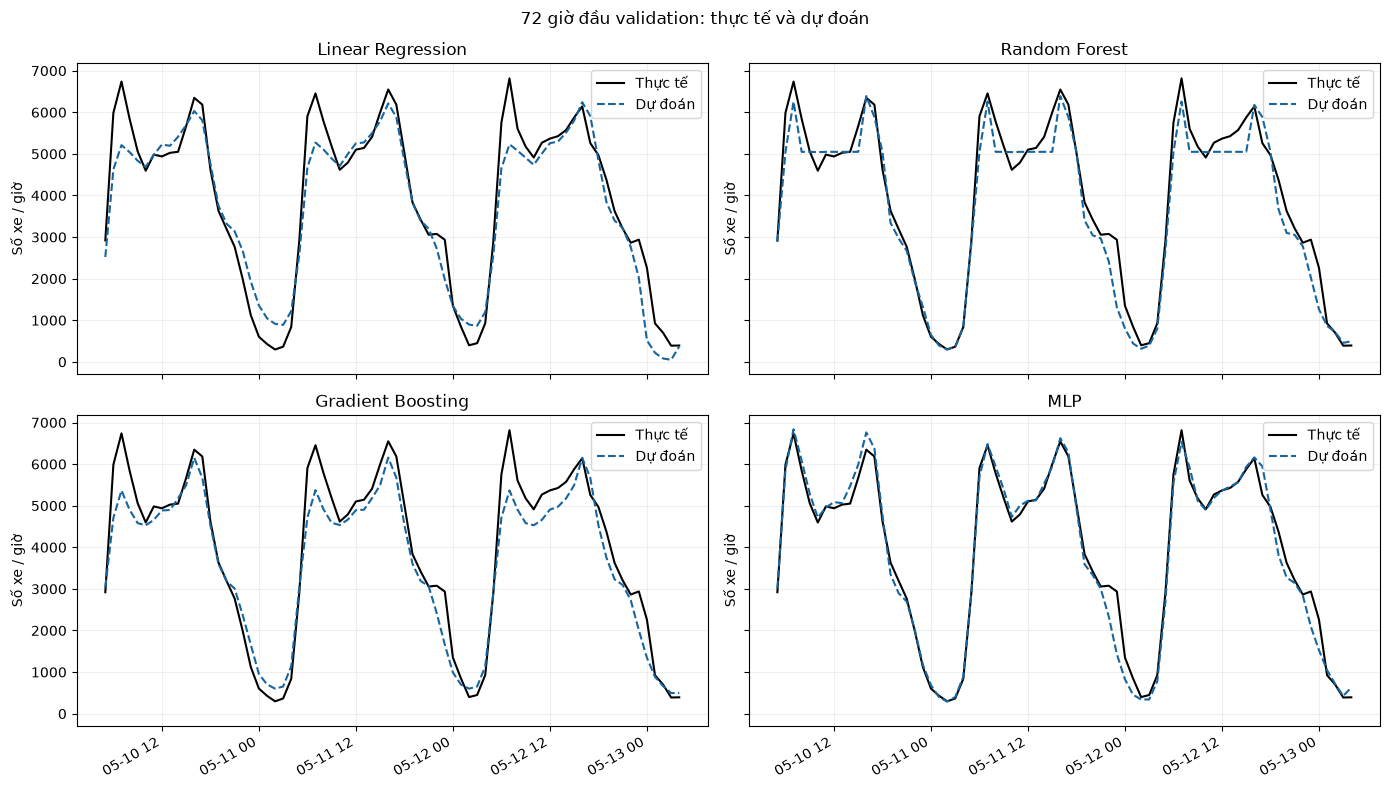

Hình đã lưu tại: /workspaces/SGU_HocMay_2026-2027/metro_interstate_traffic_volume/experiments/12-11-2026_ConfigB_4Model-Hao/ConfigB_thoi_tiet_20261112_171909_587648.png


In [8]:
mask_72h = validation.date_time < validation.date_time.min() + pd.Timedelta(hours=72)
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
for ax, (ten, du_doan) in zip(axes.flat, du_doan_cac_mo_hinh.items()):
    ax.plot(validation.loc[mask_72h, 'date_time'], y_val.loc[mask_72h],
            color='black', label='Thực tế')
    ax.plot(validation.loc[mask_72h, 'date_time'], du_doan[mask_72h.to_numpy()],
            color='#17659e', linestyle='--', label='Dự đoán')
    ax.set_title(ten)
    ax.set_ylabel('Số xe / giờ')
    ax.grid(alpha=0.2)
    ax.legend()
fig.suptitle('72 giờ đầu validation: thực tế và dự đoán')
fig.autofmt_xdate()
fig.tight_layout()
thu_muc_hinh = du_an / 'experiments' / '12-11-2026_ConfigB_4Model-Hao'
thu_muc_hinh.mkdir(parents=True, exist_ok=True)
ten_hinh = thu_muc_hinh / f"ConfigB_thoi_tiet_{datetime.now():%Y%m%d_%H%M%S_%f}.png"
fig.savefig(ten_hinh, dpi=150, bbox_inches='tight')
plt.show()
print('Hình đã lưu tại:', ten_hinh)

### Nhận xét từ hình: 
+ MLP nhìn chung bám khá sát thực tế, kể cả ở các đỉnh và đáy.
+ Random Forest dự đoán hơi phẳng ở vùng lưu lượng cao; Linear Regression và Gradient Boosting còn dự đoán thấp hơn thực tế tại một số đỉnh.